In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np

## Data settings

In [3]:
col2_setting = "large"

final_times = [4.5, 4.5, 4.5]
h_dts = [0.125, 0.15 if col2_setting == "small" else 0.125, 0.15]
tn_dts = [0.01, 0.01, 0.01]

plot_times = [4, 4, 4]
# plot_times = final_times
h_data_limits = [int(np.ceil(pt / hdt))+1 for pt, hdt in zip(plot_times, h_dts)]
tn_data_steps = [int(hdt / tndt) for hdt, tndt in zip(h_dts, tn_dts)]
tn_data_limits = [int(np.ceil(ft / tndt))+1 for ft, tndt in zip(plot_times, tn_dts)]

hardware_datas_filepath = ["Data/col1_hdata.pkl", f"Data/col2_hdata_{col2_setting}_old_confidence_0.7.pkl", "Data/col3_hdata_m_0.3_g_0.5_confidence_0.7.pkl"]
tn_datas_filepath = ["Data/col1_tndata.txt", f"Data/col2_tndata_{col2_setting}.txt", "Data/col3_tndata_m_0.3_g_0.5.txt"]

In [4]:
h_data_limits

[33, 33, 28]

In [5]:
tn_data_limits

[401, 401, 401]

## Load data

In [6]:
import numpy as np
import pickle

hobs = []
hconfs = []
tnobs = []

for hfp, tfp in zip(hardware_datas_filepath, tn_datas_filepath):
    with open(hfp, "rb") as f:
        data = pickle.load(f)
        hobs.append(data[0][0])
        hconfs.append(data[1][0])
    with open(tfp, "r") as f:
        tnobs.append(np.loadtxt(f))

## Process data

In [7]:
((1-hobs[0][:h_data_limits[0]])/2)[-5:, 4]

array([0.40334675, 0.38530583, 0.37664073,        nan, 0.42147392])

In [8]:
((1-hconfs[0][:h_data_limits[0], :, ::-1])/2)[-5:, 4, :]

array([[0.37585231, 0.42375151],
       [0.35899632, 0.40803713],
       [0.34873358, 0.40654794],
       [       nan,        nan],
       [0.39798856, 0.44050781]])

In [9]:
hconfs[0][-2, 4, :]

array([0.02762179, 0.04640495])

In [10]:
(hconfs[0][:h_data_limits[0], :, ::-1])[-2, :, :] = (hconfs[0][:h_data_limits[0], :, :])[-3, :, ::-1]

In [11]:
((1-hconfs[0][:h_data_limits[0], :, ::-1])/2)[-5:, 4, :]

array([[0.37585231, 0.42375151],
       [0.35899632, 0.40803713],
       [0.34873358, 0.40654794],
       [0.34873358, 0.40654794],
       [0.39798856, 0.44050781]])

## Auxiliary plot function

In [12]:
def plot_individual_qubits_htn_comparison_to_ax(
    ax, 
    observable_matrix_hardware, 
    observable_matrix_tn, 
    qubit_indices, 
    observable_confidence_hardware=None, 
    x_ticks=None, 
    x_label=None,
    y_label=None, 
    y_lim=None,
    labels=None, 
    cmap=None, 
    title="", 
    legend=None
):
    observable_matrix_hardware = np.array(observable_matrix_hardware)[:, qubit_indices]
    observable_matrix_tn = np.array(observable_matrix_tn)[:, qubit_indices]
    if observable_confidence_hardware is not None:
        observable_confidence_hardware = np.array(observable_confidence_hardware)[:, qubit_indices, :]
        if observable_matrix_hardware.shape != observable_confidence_hardware.shape[:-1]:
            raise ValueError("Observable matrix and standard deviation matrix must have the same shape")
    
    if labels is not None:
        if len(labels) != observable_matrix_hardware.shape[1]:
            raise ValueError("labels must have the same length as number of observable")
    
    if cmap is None:
        cmap = plt.get_cmap("Set2")

    if x_ticks is not None:
        if len(x_ticks.shape) == 1:
            ax.set_xticks(x_ticks)
        else:
            ax.set_xticks(*x_ticks)
        x_hardware = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_hardware.shape[0])
        x_tn = np.linspace(x_ticks[0], x_ticks[-1], observable_matrix_tn.shape[0])
    else:
        x_hardware = np.arange(observable_matrix_hardware.shape[0])
        x_tn = np.arange(observable_matrix_tn.shape[0])

    if labels is None:
        labels = [f"$O_{i}$" for i in range(observable_matrix_hardware.shape[1])]

    hlines = []
    for i in range(observable_matrix_hardware.shape[1]):
        color = cmap((i % 8))
        ax.plot(x_tn, observable_matrix_tn[:, i], "-", markersize=10, markeredgecolor="black", color=color, label=labels[i], linewidth=3, zorder=2)
        yh = observable_matrix_hardware[:, i]
        if observable_confidence_hardware is not None:
            upper_error_bound_mask = np.less(yh.reshape((len(yh), 1)), observable_confidence_hardware[:, i, :])
            lower_error_bound_mask = np.greater(yh.reshape((len(yh), 1)), observable_confidence_hardware[:, i, :])
            consistency_mask = ~np.logical_xor(np.sum(upper_error_bound_mask, axis=1) == 0, np.sum(lower_error_bound_mask, axis=1) == 0)
            upper_error = observable_confidence_hardware[:, i, 1][consistency_mask] - yh[consistency_mask]
            lower_error = yh[consistency_mask] - observable_confidence_hardware[:, i, 0][consistency_mask]
            yerr = np.zeros_like(upper_error_bound_mask, dtype=float)
            yerr[consistency_mask, 0] = lower_error
            yerr[consistency_mask, 1] = upper_error
            # hlines.append(ax.errorbar(x_hardware, observable_matrix_hardware[:, i], yerr=yerr.T, fmt="o", markersize=8, elinewidth=2, markeredgecolor="black", color=color, label=labels[i], capsize=5, capthick=2))
            ax.fill_between(x_hardware, observable_confidence_hardware[:, i, 0], observable_confidence_hardware[:, i, 1], color=cmap(i), alpha=0.3)
            hlines.append(ax.plot(x_hardware, observable_matrix_hardware[:, i], "o", markersize=8, markeredgecolor="black", color=color, label=labels[i], zorder=3))
        else:
            hlines.append(ax.plot(x_hardware, observable_matrix_hardware[:, i], "o", markersize=8, markeredgecolor="black", color=color, label=labels[i], zorder=3))
    
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label, labelpad=10)
    ax.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
    if y_lim == "data":
        min_data = np.nanmin(observable_matrix_hardware)
        max_data = np.nanmax(observable_matrix_hardware)
        ax.set_ylim([min_data - 0.05*(max_data - min_data), max_data + 0.05*(max_data - min_data)])
    elif y_lim is not None:
        ax.set_ylim(y_lim)
    if title:
        ax.set_title(title, pad=10, fontsize=26)
    if legend:
        ax.legend(handles=[ax.plot([], "o-", color=cmap(i % 8))[0] for i in range(observable_matrix_hardware.shape[1])], labels=[line[0].get_label() if isinstance(line, list) else line.get_label() for line in hlines], loc="upper right", fontsize=16)

def get_lims_from_ticks(ticks, relmargin, y_lim=None):
    if y_lim is not None:
        mask = np.logical_and(ticks >= y_lim[0], ticks <= y_lim[1])
        ticks = ticks[mask]
    min_tick = ticks[0]
    max_tick = ticks[-1]
    delta_ticks = max_tick - min_tick
    return [min_tick - relmargin * delta_ticks, max_tick + relmargin * delta_ticks]

## Data plots

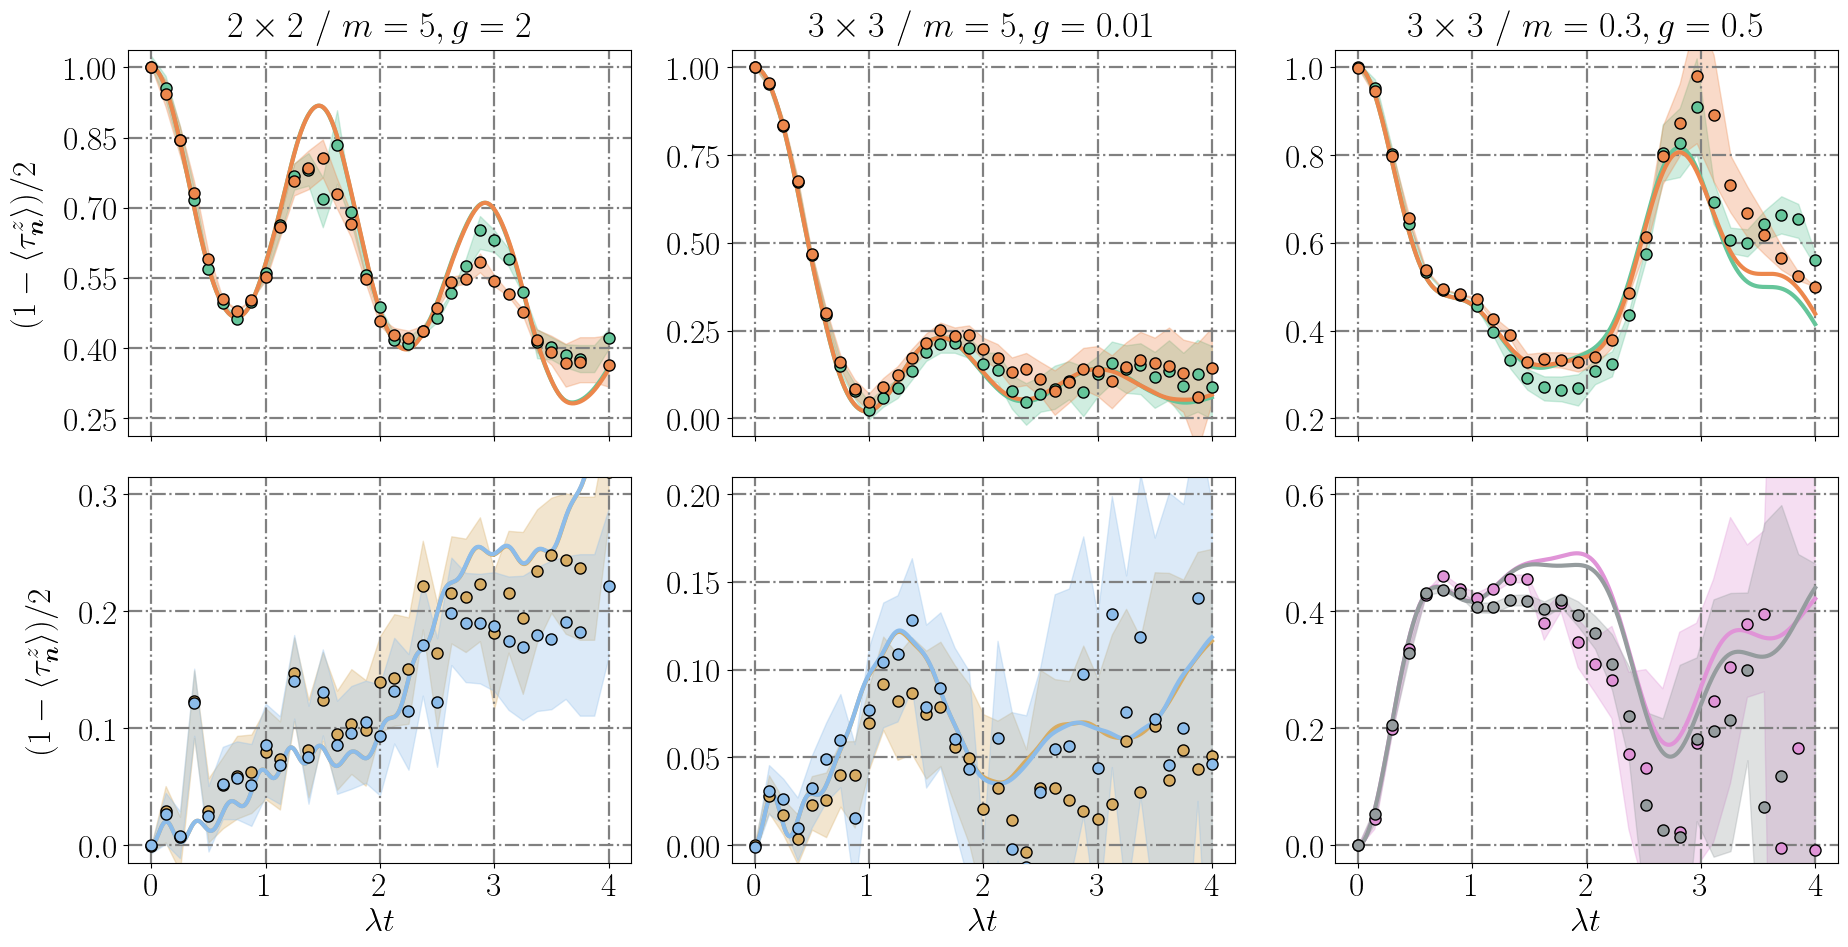

In [13]:
import matplotlib.pyplot as plt

# colors = ["#88B4DD", "#4E8988", "#56B389", "#8C8B5F", "#DC7C46", "#CD6B6E", "#CO7CB8", "#E1A132"]
colors = ["#8CBCEA", "#65C59A", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]

row1_cmap = lambda x: [colors[1], colors[3]][x]
row2_cmap = lambda x: [colors[0], colors[-3]][::-1][x] #plt.get_cmap("Set2")(6 - 4*x)
row2_col3_cmap = lambda x: [colors[-4], colors[-1]][x] #lambda x: "darkkhaki" if x == 0 else "plum"

plt.rc("text", usetex=True)
plt.rc("font", size=24, family="serif", weight="bold")
plt.rc("text.latex", preamble=r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}\usepackage{physics}")

fig, axs = plt.subplots(2, 3, figsize=(19, 10))

nxlabels = 5
margin = 0.05

# Col 1
qubit_indices00 = [4, 30]
x_ticks00 = np.linspace(0, plot_times[0], 6)
y_lim00 = [0.2, 1.05]
title00 = r"$2 \times 2$ / $m = 5, g = 2$"
y_label00 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_qubits_htn_comparison_to_ax(axs[0, 0], 
                                            (1-hobs[0][:h_data_limits[0]])/2, (1-tnobs[0][:tn_data_limits[0], :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices00,
                                            observable_confidence_hardware=(1-hconfs[0][:h_data_limits[0], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks00,
                                            x_label=None,
                                            y_label=r"$\langle n \rangle$",
                                            y_lim=y_lim00,
                                            cmap=row1_cmap,
                                            title=title00)
axs[0, 0].set_xticks(np.linspace(0, plot_times[0], nxlabels), [])
axs[0, 0].set_yticks(np.linspace(0.25, 1, 6))
axs[0, 0].set_ylabel(y_label00, labelpad=15)
axs[0, 0].set_ylim(get_lims_from_ticks(axs[0, 0].get_yticks(), margin, y_lim=y_lim00))

qubit_indices10 = [20, 14] #[14, 20]
x_ticks10 = np.linspace(0, plot_times[0], 6)
y_lim10 = [-0.017, 0.317]
title10 = None
y_label10 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_qubits_htn_comparison_to_ax(axs[1, 0], 
                                            (1-hobs[0][:h_data_limits[0]])/2, (1-tnobs[0][:tn_data_limits[0], :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices10,
                                            observable_confidence_hardware=(1-hconfs[0][:h_data_limits[0], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks10,
                                            x_label=None,
                                            y_label=r"$\langle n \rangle$",
                                            y_lim=y_lim10,
                                            cmap=row2_cmap,
                                            title=title10)
axs[1, 0].set_xticks(np.linspace(0, plot_times[0], nxlabels))
axs[1, 0].set_xlabel(r"$\lambda t$")
axs[1, 0].set_ylabel(y_label10, labelpad=15)
axs[1, 0].set_ylim(get_lims_from_ticks(axs[1, 0].get_yticks(), margin, y_lim=y_lim10))

# Col 2
qubit_indices01 = [4, 30] if col2_setting == "small" else [4, 63]
x_ticks01 = np.linspace(0, plot_times[1], 6)
y_lim01 = [-0.05, 1.075]
title01 = r"$3 \times 3$ / $m = 5, g = 0.01$"
y_label01 = None
plot_individual_qubits_htn_comparison_to_ax(axs[0, 1], 
                                            (1-hobs[1][:h_data_limits[1]])/2, (1-tnobs[1][:tn_data_limits[1], :])/2,
                                            # hobs[1], tnobs[1][:tn_data_limits[1], :],
                                            qubit_indices=qubit_indices01,
                                            observable_confidence_hardware=(1-hconfs[1][:h_data_limits[1], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[1],
                                            x_ticks=x_ticks01,
                                            x_label=None,
                                            y_label=y_label01,
                                            y_lim=y_lim01,
                                            cmap=row1_cmap,
                                            title=title01)
axs[0, 1].set_xticks(np.linspace(0, plot_times[1], nxlabels), [])
axs[0, 1].set_ylabel(y_label01, labelpad=15)
axs[0, 1].set_ylim(get_lims_from_ticks(axs[0, 1].get_yticks(), margin, y_lim=y_lim01))

qubit_indices11 = [14, 20] if col2_setting == "small" else [59, 8]#[8, 59] #[21, 48] #[21, 48]
x_ticks11 = np.linspace(0, plot_times[1], 6)
y_lim11 = [0, 0.2] #if col2_setting == "small" else None
title11 = None
y_label11 = None
plot_individual_qubits_htn_comparison_to_ax(axs[1, 1], 
                                            (1-hobs[1][:h_data_limits[1]])/2, (1-tnobs[1][:tn_data_limits[1], :])/2,
                                            # hobs[1], tnobs[1][:tn_data_limits[1], :],
                                            qubit_indices=qubit_indices11,
                                            observable_confidence_hardware=(1-hconfs[1][:h_data_limits[1], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[1],
                                            x_ticks=x_ticks11,
                                            x_label=None,
                                            y_label=y_label11,
                                            y_lim=y_lim11,
                                            cmap=row2_cmap,
                                            title=title11)
axs[1, 1].set_xticks(np.linspace(0, plot_times[1], nxlabels))
axs[1, 1].set_xlabel(r"$\lambda t$")
axs[1, 1].set_ylabel(y_label11, labelpad=15)
axs[1, 1].set_ylim(get_lims_from_ticks(axs[1, 1].get_yticks(), margin, y_lim=y_lim11 if isinstance(y_lim11, list) else None))

# Col 3
qubit_indices02 = [4, 63]
x_ticks02 = np.linspace(0, plot_times[2], 6)
y_lim02 = [0.2, 1.025]
title02 = r"$3 \times 3$ / $m = 0.3, g = 0.5$"
y_label02 = None
plot_individual_qubits_htn_comparison_to_ax(axs[0, 2], 
                                            (1-hobs[2][:h_data_limits[2]])/2, (1-tnobs[2][:tn_data_limits[2], :])/2,
                                            # hobs[2], tnobs[2][:tn_data_limits[2], :],
                                            qubit_indices=qubit_indices02,
                                            observable_confidence_hardware=(1-hconfs[2][:h_data_limits[2], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[2],
                                            x_ticks=x_ticks02,
                                            x_label=None,
                                            y_label=y_label02,
                                            y_lim=y_lim02,
                                            cmap=row1_cmap,
                                            title=title02)
axs[0, 2].set_xticks(np.linspace(0, plot_times[2], nxlabels), [])
axs[0, 2].set_ylabel(y_label02, labelpad=15)
axs[0, 2].set_ylim(get_lims_from_ticks(axs[0, 2].get_yticks(), margin, y_lim=y_lim02))

qubit_indices12 = [21, 48]
x_ticks12 = np.linspace(0, plot_times[2], 6)
y_lim12 = [-0.025, 0.7]
title12 = None
y_label12 = None
plot_individual_qubits_htn_comparison_to_ax(axs[1, 2], 
                                            (1-hobs[2][:h_data_limits[2]])/2, (1-tnobs[2][:tn_data_limits[2], :])/2,
                                            # hobs[2], tnobs[2][:tn_data_limits[1], :],
                                            qubit_indices=qubit_indices12,
                                            observable_confidence_hardware=(1-hconfs[2][:h_data_limits[2], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[1],
                                            x_ticks=x_ticks12,
                                            x_label=None,
                                            y_label=y_label12,
                                            y_lim=y_lim12,
                                            cmap=row2_col3_cmap,
                                            title=title12)
axs[1, 2].set_xticks(np.linspace(0, plot_times[2], nxlabels))
axs[1, 2].set_xlabel(r"$\lambda t$")
axs[1, 2].set_ylabel(y_label12, labelpad=15)
axs[1, 2].set_ylim(get_lims_from_ticks(axs[1, 2].get_yticks(), margin, y_lim=y_lim12))

plt.tight_layout()
plt.savefig(f"data_single_string_dynamics_{col2_setting}.svg", dpi=300)

In [ ]:
np.array(plt.get_cmap("Set2")(1/8))*255

array([252., 141.,  98., 255.])

## Legends

### Col 1

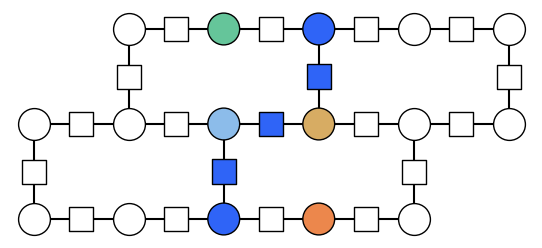

In [ ]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices00 + qubit_indices10

string_qubits = [4, 10, 17, 24, 30]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)], number_highlighted=False, filepath="col1_legend.svg", number_qubits=False)

## Col 2

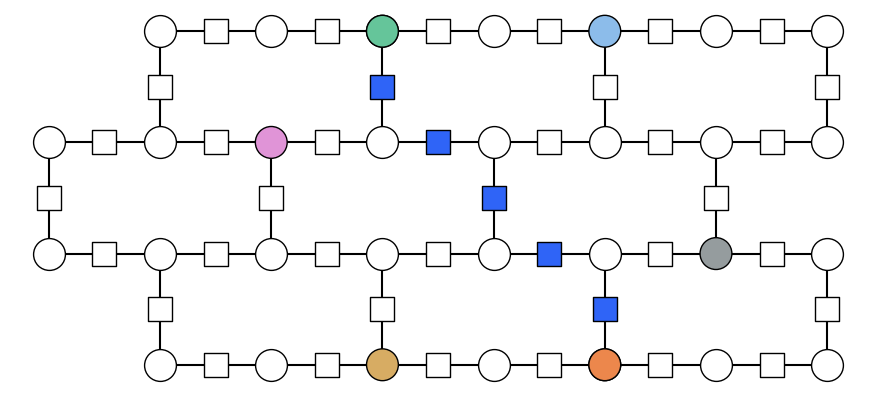

In [14]:
from z2hex.geometry import HeavyHexLattice

px, py = 3, 3
highlighted_qubits = qubit_indices01 + qubit_indices11 + qubit_indices12

string_qubits = [4, 14, 24, 34, 45, 53, 63]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)] + [row2_col3_cmap(i) for i in range(2)], number_qubits=False, number_highlighted=False, filepath="col2_legend.svg")

In [15]:
len(lattice.edge_qbinds)

38

## Col 3

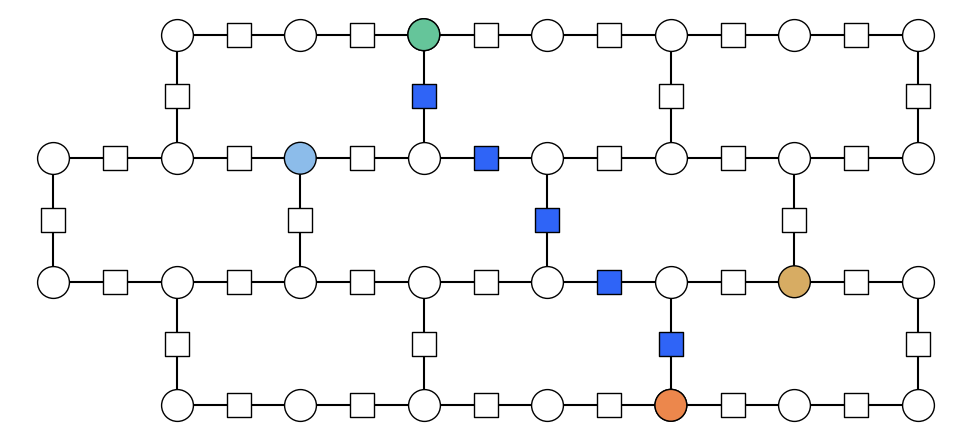

In [12]:
from z2hex.geometry import HeavyHexLattice

px, py = 3, 3
highlighted_qubits = qubit_indices02 + qubit_indices12

string_qubits = [4, 14, 24, 34, 45, 53, 63]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)], number_highlighted=False, filepath="col3_legend.svg")

# Appendix figure

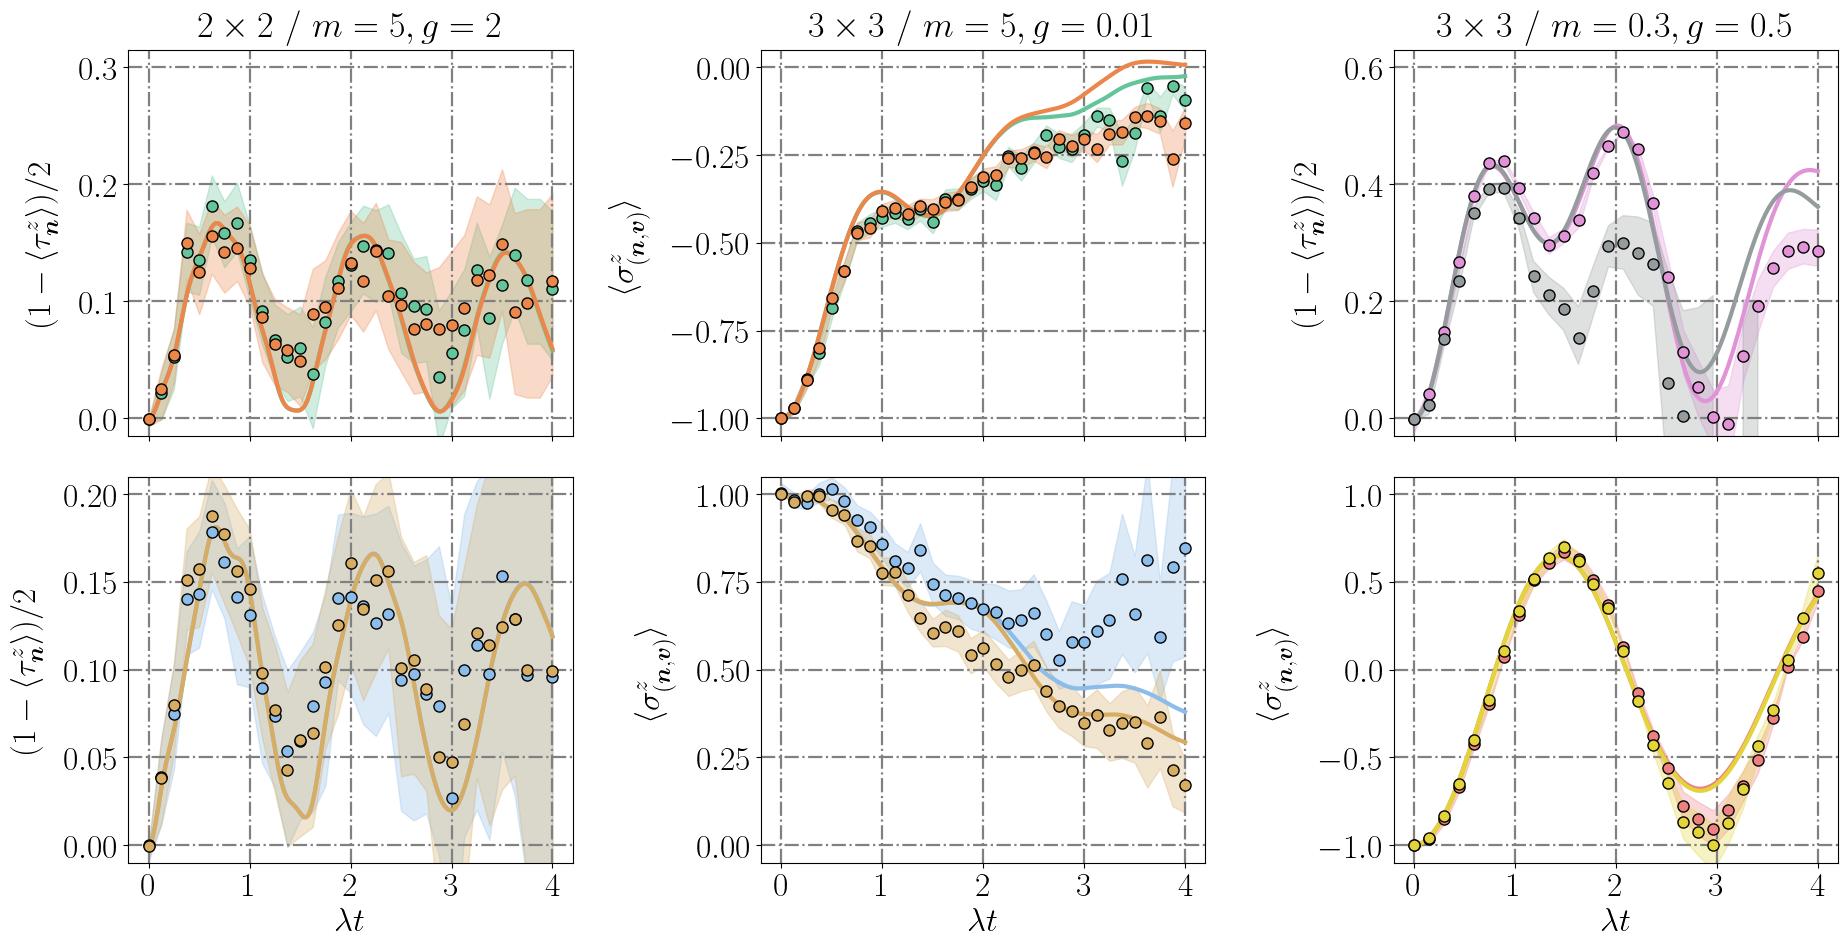

In [ ]:
import matplotlib.pyplot as plt

# colors = ["#88B4DD", "#4E8988", "#56B389", "#8C8B5F", "#DC7C46", "#CD6B6E", "#CO7CB8", "#E1A132"]
colors = ["#8CBCEA", "#65C59A", "#e2d439", "#EC874C", "#EF8082", "#E094D7", "#D7AC63", "#AC9CF4", "#959C9E"]

row1_cmap = lambda x: [colors[1], colors[3]][x]
row2_cmap = lambda x: [colors[0], colors[-3]][x] #plt.get_cmap("Set2")(6 - 4*x)
row1_col3_cmap = lambda x: [colors[-4], colors[-1]][x] #lambda x: "darkkhaki" if x == 0 else "plum"
row2_col3_cmap = lambda x: [colors[4], colors[2]][x] #lambda x: "darkkhaki" if x == 0 else "plum"

plt.rc("text", usetex=True)
plt.rc("font", size=24, family="serif", weight="bold")
plt.rc("text.latex", preamble=r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}\usepackage{physics}")

fig, axs = plt.subplots(2, 3, figsize=(19, 10))

nxlabels = 5
margin = 0.05

# Col 1
qubit_indices00 = [2, 32]
x_ticks00 = np.linspace(0, plot_times[0], 6)
y_lim00 = [0, 1]
title00 = r"$2 \times 2$ / $m = 5, g = 2$"
y_label00 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_qubits_htn_comparison_to_ax(axs[0, 0], 
                                            (1-hobs[0][:h_data_limits[0]])/2, (1-tnobs[0][:tn_data_limits[0], :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices00,
                                            observable_confidence_hardware=(1-hconfs[0][:h_data_limits[0], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks00,
                                            x_label=None,
                                            y_label=r"$\langle n \rangle$",
                                            y_lim=y_lim00,
                                            cmap=row1_cmap,
                                            title=title00)
axs[0, 0].set_xticks(np.linspace(0, plot_times[0], nxlabels), [])
axs[0, 0].set_yticks(np.linspace(0, 0.3, 4))
axs[0, 0].set_ylabel(y_label00, labelpad=15)
axs[0, 0].set_ylim(get_lims_from_ticks(axs[0, 0].get_yticks(), margin, y_lim=y_lim00))

qubit_indices10 = [16, 18]
x_ticks10 = np.linspace(0, plot_times[0], 6)
y_lim10 = [-0.017, 0.317]
title10 = None
y_label10 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_qubits_htn_comparison_to_ax(axs[1, 0], 
                                            (1-hobs[0][:h_data_limits[0]])/2, (1-tnobs[0][:tn_data_limits[0], :])/2,
                                            # hobs[0], tnobs[0][:tn_data_limits[0], :],
                                            qubit_indices=qubit_indices10,
                                            observable_confidence_hardware=(1-hconfs[0][:h_data_limits[0], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[0],
                                            x_ticks=x_ticks10,
                                            x_label=None,
                                            y_label=r"$\langle n \rangle$",
                                            y_lim=y_lim10,
                                            cmap=row2_cmap,
                                            title=title10)
axs[1, 0].set_xticks(np.linspace(0, plot_times[0], nxlabels))
axs[1, 0].set_xlabel(r"$\lambda t$")
axs[1, 0].set_yticks(np.linspace(0, 0.2, 5))
axs[1, 0].set_ylabel(y_label10, labelpad=15)
axs[1, 0].set_ylim(get_lims_from_ticks(axs[1, 0].get_yticks(), margin, y_lim=y_lim10))

# Col 2
qubit_indices01 = [14, 53]
x_ticks01 = np.linspace(0, plot_times[1], 6)
y_lim01 = [-1, 0.1]
title01 = r"$3 \times 3$ / $m = 5, g = 0.01$"
y_label01 = r"$\langle \sigma_{(\boldsymbol{n}, \boldsymbol{v})}^z \rangle$"
plot_individual_qubits_htn_comparison_to_ax(axs[0, 1], 
                                            hobs[1][:h_data_limits[1]], tnobs[1][:tn_data_limits[1], :],
                                            # hobs[1], tnobs[1][:tn_data_limits[1], :],
                                            qubit_indices=qubit_indices01,
                                            observable_confidence_hardware=hconfs[1][:h_data_limits[1], :, ::-1],
                                            # observable_confidence_hardware=hconfs[1],
                                            x_ticks=x_ticks01,
                                            x_label=None,
                                            y_label=y_label01,
                                            y_lim=y_lim01,
                                            cmap=row1_cmap,
                                            title=title01)
axs[0, 1].set_xticks(np.linspace(0, plot_times[1], nxlabels), [])
# axs[0, 1].set_yticks(np.linspace(0.5, 1, 6))
axs[0, 1].set_ylabel(y_label01, labelpad=15)
axs[0, 1].set_ylim(get_lims_from_ticks(axs[0, 1].get_yticks(), margin, y_lim=y_lim01))

qubit_indices11 = [22, 47]
x_ticks11 = np.linspace(0, plot_times[1], 6)
y_lim11 = [0, 1] #if col2_setting == "small" else None
title11 = None
y_label11 = r"$\langle \sigma_{(\boldsymbol{n}, \boldsymbol{v})}^z \rangle$"
plot_individual_qubits_htn_comparison_to_ax(axs[1, 1], 
                                            hobs[1][:h_data_limits[1]], tnobs[1][:tn_data_limits[1], :],
                                            # hobs[1], tnobs[1][:tn_data_limits[1], :],
                                            qubit_indices=qubit_indices11,
                                            observable_confidence_hardware=hconfs[1][:h_data_limits[1], :, ::-1],
                                            # observable_confidence_hardware=hconfs[1],
                                            x_ticks=x_ticks11,
                                            x_label=None,
                                            y_label=y_label11,
                                            y_lim=y_lim11,
                                            cmap=row2_cmap,
                                            title=title11)
axs[1, 1].set_xticks(np.linspace(0, plot_times[1], nxlabels))
axs[1, 1].set_xlabel(r"$\lambda t$")
axs[1, 1].set_ylabel(y_label11, labelpad=15)
axs[1, 1].set_ylim(get_lims_from_ticks(axs[1, 1].get_yticks(), margin, y_lim=y_lim11 if isinstance(y_lim11, list) else None))

# Col 3
qubit_indices02 = [12, 55]
x_ticks02 = np.linspace(0, plot_times[2], 6)
y_lim02 = [0, 0.6]
title02 = r"$3 \times 3$ / $m = 0.3, g = 0.5$"
y_label02 = r"$(1 - \langle \tau_{\boldsymbol{n}}^z \rangle)/2$"
plot_individual_qubits_htn_comparison_to_ax(axs[0, 2], 
                                            (1-hobs[2][:h_data_limits[2]])/2, (1-tnobs[2][:tn_data_limits[2], :])/2,
                                            # hobs[2], tnobs[2][:tn_data_limits[2], :],
                                            qubit_indices=qubit_indices02,
                                            observable_confidence_hardware=(1-hconfs[2][:h_data_limits[2], :, ::-1])/2,
                                            # observable_confidence_hardware=hconfs[2],
                                            x_ticks=x_ticks02,
                                            x_label=None,
                                            y_label=y_label02,
                                            y_lim=y_lim02,
                                            cmap=row1_col3_cmap,
                                            title=title02)
axs[0, 2].set_xticks(np.linspace(0, plot_times[2], nxlabels), [])
axs[0, 2].set_ylabel(y_label02, labelpad=15)
axs[0, 2].set_yticks(np.linspace(0, 0.6, 4))
axs[0, 2].set_ylim(get_lims_from_ticks(axs[0, 2].get_yticks(), margin, y_lim=y_lim02))

qubit_indices12 = [24, 45]
x_ticks12 = np.linspace(0, plot_times[2], 6)
y_lim12 = [-1, 1]
title12 = None
y_label12 = r"$\langle \sigma_{(\boldsymbol{n}, \boldsymbol{v})}^z \rangle$"
plot_individual_qubits_htn_comparison_to_ax(axs[1, 2], 
                                            hobs[2][:h_data_limits[2]], tnobs[2][:tn_data_limits[2], :],
                                            # hobs[2], tnobs[2][:tn_data_limits[1], :],
                                            qubit_indices=qubit_indices12,
                                            observable_confidence_hardware=hconfs[2][:h_data_limits[2], :, ::-1],
                                            # observable_confidence_hardware=hconfs[1],
                                            x_ticks=x_ticks12,
                                            x_label=None,
                                            y_label=y_label12,
                                            y_lim=y_lim12,
                                            cmap=row2_col3_cmap,
                                            title=title12)
axs[1, 2].set_xticks(np.linspace(0, plot_times[2], nxlabels))
axs[1, 2].set_xlabel(r"$\lambda t$")
axs[1, 2].set_ylabel(y_label12, labelpad=15)
axs[1, 2].set_ylim(get_lims_from_ticks(axs[1, 2].get_yticks(), margin, y_lim=y_lim12))

plt.tight_layout()
plt.savefig(f"appendix_1string_supp_data.svg", dpi=300)

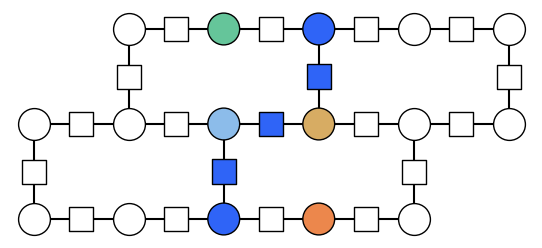

In [93]:
from z2hex.geometry import HeavyHexLattice

px, py = 2, 2
highlighted_qubits = qubit_indices00 + qubit_indices10

string_qubits = [4, 10, 17, 24, 30]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)], number_highlighted=False, filepath="col1_legend_supp.svg", number_qubits=False)

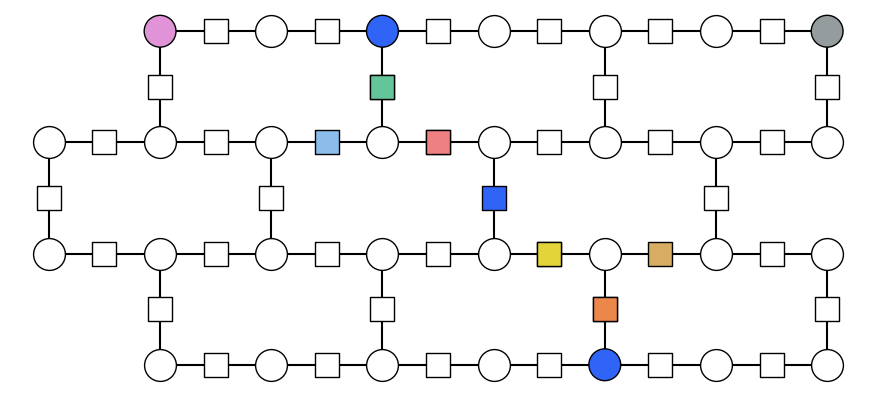

In [19]:
from z2hex.geometry import HeavyHexLattice

px, py = 3, 3
highlighted_qubits = qubit_indices01 + qubit_indices11 + qubit_indices02 + qubit_indices12

string_qubits = [4, 14, 24, 34, 45, 53, 63]

lattice = HeavyHexLattice(px, py)
lattice.plot_highlighted_qubits(string_qubits + highlighted_qubits, colors=["#2f64f7"]*len(string_qubits) + [row1_cmap(i % 8) for i in range(2)] + [row2_cmap(i % 8) for i in range(2)] + [row1_col3_cmap(i % 8) for i in range(2)] + [row2_col3_cmap(i) for i in range(2)], number_qubits=False, number_highlighted=False, filepath="col2_legend_supp.svg")